# Compare Read Sorting Performances

## 0. Imports and Path Assignments

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay
import sys
import os
sys.path.append(os.path.abspath(os.path.join("..")))
from helper.visualization import *
from helper.metrics import * 

from warnings import simplefilter
simplefilter("ignore")

In [2]:
# --- Parameters ---
data_dir = Path.cwd()/ "results"
fig_dir = Path.cwd() / "figures" 
fig_dir.mkdir(exist_ok=True, parents=True)
fig_dir_comparison = fig_dir / "comparison"
fig_dir_comparison.mkdir(exist_ok=True)

## 1. Load performance metrics for every read-sorting method

In [3]:
methods = ["xengsort", "icrg", "bamcmp", "xenofilter"]
# "bamcmp","icrg", 
dfs = [pd.read_csv(data_dir / f"{method}.csv") for method in methods]
df = pd.concat(dfs)
df.to_csv(data_dir / "merged.csv", index=False)

In [4]:
df["Sample_Prefix"].unique()

array(['wgbs-human-pancreas-organoid3_wgbs-mouse-pancreas-organoid3',
       'wgbs-human-brca-cl1_wgbs-mouse-bm-hsc1',
       'wgbs-human-pancreas-organoid2_wgbs-mouse-pancreas-organoid2',
       'wgbs-human-pancreas-organoid1_wgbs-mouse-pancreas-organoid1'],
      dtype=object)

In [6]:
sample_map = {
    "wgbs-human-brca-cl1_wgbs-mouse-bm-hsc1" : "Mixture 1",
    "wgbs-human-pancreas-organoid1_wgbs-mouse-pancreas-organoid1" : "Mixture 2",
    "wgbs-human-pancreas-organoid2_wgbs-mouse-pancreas-organoid2" : "Mixture 3",
    "wgbs-human-pancreas-organoid3_wgbs-mouse-pancreas-organoid3" : "Mixture 4"
    }
df["Sample_Name"] = df["Sample_Prefix"].map(sample_map)

## 2. Visualization

Important Metrics: 
- Loss of Human Reads (Human_Loss and Human_Loss_pct)
- Precision
- False Positive Rate (FPR)

### Across Mixture Datasets

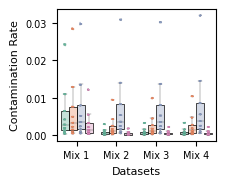

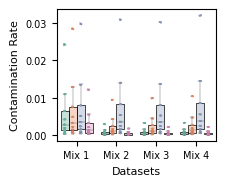

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import PathPatch, Patch

def boxplot_tools(df, x = "Sample_Name", y = "Contamination_Rate", hue="Method", 
                  figsize=None, xlabel=None, ylabel=None, xlabel_fs = 8, ylabel_fs = 8, xtick_fs = 7, ytick_fs = 7,
                  boxplot_width=0.8, whisker_lw = 0.3, cap_lw = 0.3, median_lw = 0.3, box_lw=0.3,
                  palette = None, dot_size=1, dot_alpha=0.7, dot_lw=0.05, legend=True, 
                  save=False, fig_dir="./", file_path="boxplot.png"):
    if palette is None:
        palette = sns.color_palette("Set2")  
    sample_order = sorted(df[x].unique())

    fig, ax = plt.subplots(figsize=figsize)

    if xlabel is None:
        xlabel = x
    if ylabel is None:
        ylabel = y
    # Use one palette consistently
    hue_order = list(df[hue].dropna().unique())
    
    ax = sns.boxplot(
        data=df, x=x, y=y,
        hue=hue, order=sample_order, hue_order=hue_order,
        palette=palette,
        width=boxplot_width, dodge=True, showfliers=False,
        ax=ax,
        whiskerprops={"linewidth": whisker_lw},   # ← thinner whiskers
        capprops={"linewidth": cap_lw},       # ← thinner caps
        medianprops={"linewidth": median_lw},    # adjust median line
        legend=False,
        linewidth=box_lw
    )


    # Make only the box FILL transparent (alpha=0.4), keep borders opaque and thinner
    box_patches = [p for p in ax.patches if isinstance(p, PathPatch)]
    for p in box_patches:
        fc = p.get_facecolor()  # RGBA
        p.set_facecolor((fc[0], fc[1], fc[2], 0.4))     # transparent fill
        p.set_edgecolor((0, 0, 0, 1))                   # opaque border (black)
        p.set_linewidth(0.5)                            # thinner border

    sns.stripplot(
        data=df,
        x=x,
        y=y,
        hue=hue,
        order=sample_order,
        hue_order=hue_order,
        palette=palette,
        dodge=True,
        jitter=True,
        
        size=dot_size,
        alpha=dot_alpha,
        linewidth=dot_lw,      # ← remove edge thickness
        legend=False,
        ax=ax
    )

    # Labels / ticks
    ax.set_ylabel(ylabel, fontsize=ylabel_fs)
    ax.set_xlabel(xlabel, fontsize=xlabel_fs)
    ax.tick_params(axis="x", labelsize=xtick_fs)
    ax.tick_params(axis="y", labelsize=ytick_fs)

# # Remove seaborn's legend and add a custom opaque one
# if ax.legend_ is not None:
#     ax.legend_.remove()
    if legend:
        legend_handles = [
            Patch(
                facecolor=c,
                edgecolor="black",
                linewidth=0.5,   # ← thinner legend box border
                alpha=1,
                label=lab
            )
            for lab, c in zip(hue_order, palette[:len(hue_order)])
        ]

        ax.legend(
            handles=legend_handles,
            title="Method",
            frameon=True,
            fontsize=8,
            title_fontsize=8
        )
    plt.tight_layout()
    if save:
        plt.savefig(fig_dir / file_path, dpi=300)
        #print(f"Saved figure to {fig_dir / file_path}")

    pos = ax.get_position()
    return ax, pos
df["Sample_ID"] = df["Sample_Name"].str.split(" ").apply(lambda x: "Mix " + x[1])

ax, pos = boxplot_tools(df, x="Sample_ID", y="Contamination_Rate", hue="Method", xlabel="Datasets", ylabel="Contamination Rate", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_contamination-rate_datasets.pdf")
boxplot_tools(df, x="Sample_ID", y="Contamination_Rate", hue="Method", xlabel="Datasets", ylabel="Contamination Rate", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_contamination-rate_datasets.png");

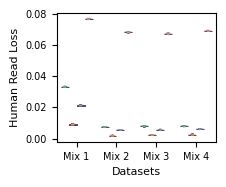

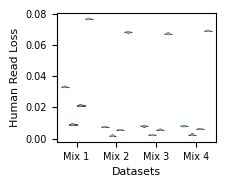

In [6]:
ax = boxplot_tools(df, x="Sample_ID", y="Human_Loss", hue="Method", xlabel="Datasets", ylabel="Human Read Loss", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_human-read-loss_datasets.pdf")
ax = boxplot_tools(df, x="Sample_ID", y="Human_Loss", hue="Method", xlabel="Datasets", ylabel="Human Read Loss", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_human-read-loss_datasets.png")

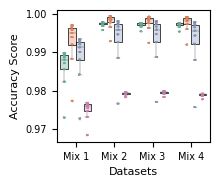

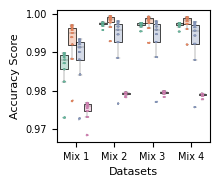

In [7]:
ax = boxplot_tools(df, x="Sample_ID", y="Score", hue="Method", xlabel="Datasets", ylabel="Accuracy Score", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_performance-score_datasets.pdf")
ax = boxplot_tools(df, x="Sample_ID", y="Score", hue="Method", xlabel="Datasets", ylabel="Accuracy Score", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_performance-score_datasets.png")

### Across Sequencing Depth

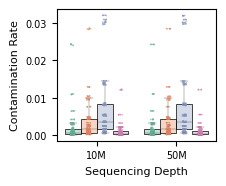

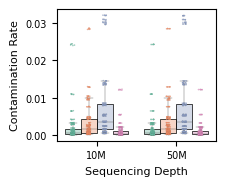

In [8]:
df["Sequencing Depth"] = (df["Total_Reads"] / 1_000_000 / 2).round().astype(int).astype(str) + "M"

ax = boxplot_tools(df, x="Sequencing Depth", y="Contamination_Rate", hue="Method", xlabel=None, ylabel="Contamination Rate", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_contamination-rate_sequencing-depths.pdf")
ax = boxplot_tools(df, x="Sequencing Depth", y="Contamination_Rate", hue="Method", xlabel=None, ylabel="Contamination Rate", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_contamination-rate_sequencing-depths.png")


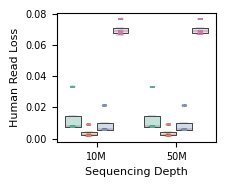

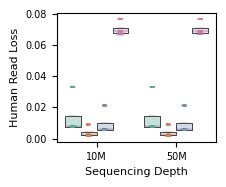

In [9]:

ax = boxplot_tools(df, x="Sequencing Depth", y="Human_Loss", hue="Method", xlabel=None, ylabel="Human Read Loss", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_human-read-loss_sequencing-depths.pdf")
ax = boxplot_tools(df, x="Sequencing Depth", y="Human_Loss", hue="Method", xlabel=None, ylabel="Human Read Loss", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_human-read-loss_sequencing-depths.png")


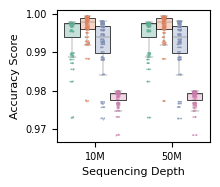

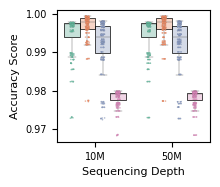

In [10]:

ax = boxplot_tools(df, x="Sequencing Depth", y="Score", hue="Method", xlabel=None, ylabel="Accuracy Score", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_performance-score_sequencing-depths.pdf")
ax = boxplot_tools(df, x="Sequencing Depth", y="Score", hue="Method", xlabel=None, ylabel="Accuracy Score", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_performance-score_sequencing-depths.png")


<Axes: xlabel='Human Content [%]', ylabel='Human Read Loss'>

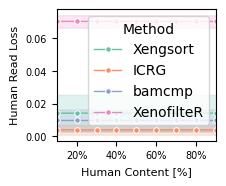

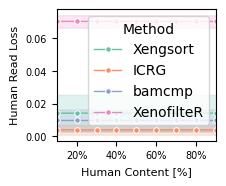

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import PercentFormatter

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import PercentFormatter

def lineplot_tools(df, x="Human_Ratio", y="Human_Loss", hue="Method", 
                   ylabel=None, ylabel_fs=8, xlabel_fs=8, xlabel="Human Ratio",
                   tick_fs=7, figsize=None, palette=sns.color_palette("Set2"), errorbar="sd", marker="o", 
                   linewidth=1, markersize=4, legend=True, pos=None,
                   save=False, fig_dir="./", file_path="lineplot.png"):
        
    fig, ax = plt.subplots(figsize=figsize)

    if pos is not None:
        ax.set_position(pos)

    if xlabel is None:
        xlabel = x
    if ylabel is None:
        ylabel = y

    if palette is None:
        palette = sns.color_palette("Set2")
    hue_order = list(df["Method"].dropna().unique())

    sns.lineplot(
        data=df,
        x=x,
        y=y,
        hue=hue,
        hue_order=hue_order,
        palette=palette,
        errorbar=errorbar,
        marker=marker,
        linewidth=linewidth,
        markersize=markersize,
        ax=ax,
        legend=legend
    )

    # ---- Set x-axis ticks every 0.1 ----
    # Set limits from 0.1 to 0.9
    ax.set_xlim(0.1, 0.9)

    # Set ticks every 0.1
    # ax.set_xticks(np.arange(0.1, 1.0, 0.1))

    # Format as percentage
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.set_ylabel(ylabel, fontsize=ylabel_fs)
    ax.set_xlabel(xlabel, fontsize=xlabel_fs)
    ax.tick_params(axis="both", labelsize=tick_fs)
    if save:
        plt.savefig(fig_dir / file_path)
        #print(f"Save plot to {fig_dir / file_path}")
    return(ax)

lineplot_tools(df, x="Human_Ratio", y="Human_Loss", hue="Method", xlabel = "Human Content [%]", ylabel="Human Read Loss", legend=True, figsize=mm_to_inches((60, 50)), pos = pos, save=True, fig_dir = fig_dir_comparison, file_path="lineplot_human-read_loss_human-ratio.pdf")
lineplot_tools(df, x="Human_Ratio", y="Human_Loss", hue="Method", xlabel = "Human Content [%]", ylabel="Human Read Loss", legend=True, figsize=mm_to_inches((60, 50)), pos = pos, save=True, fig_dir = fig_dir_comparison, file_path="lineplot_human-read_loss_human-ratio.png", )

<Axes: xlabel='Human Content [%]', ylabel='Contamination Rate'>

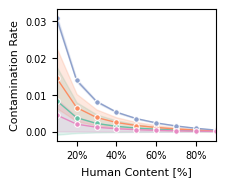

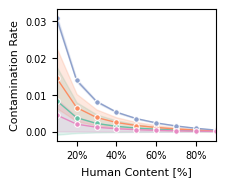

In [12]:
lineplot_tools(df, x="Human_Ratio", y="Contamination_Rate", hue="Method", xlabel = "Human Content [%]", ylabel="Contamination Rate", 
               legend=False, figsize=mm_to_inches((60, 50)), save=True, pos = pos,
               fig_dir = fig_dir_comparison, file_path="lineplot_contamination-rate_human-ratio.pdf")

lineplot_tools(df, x="Human_Ratio", y="Contamination_Rate", hue="Method", xlabel = "Human Content [%]", ylabel="Contamination Rate", 
               legend=False, figsize=mm_to_inches((60, 50)), save=True, pos = pos,
               fig_dir = fig_dir_comparison, file_path="lineplot_contamination-rate_human-ratio.png")

<Axes: xlabel='Human Ratio', ylabel='Accuracy Score'>

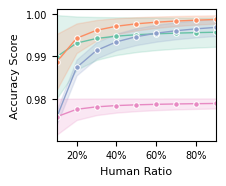

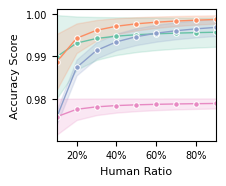

In [13]:
lineplot_tools(df, x="Human_Ratio", y="Score", hue="Method", ylabel="Accuracy Score", 
               legend=False, figsize=mm_to_inches((60, 50)), save=True, pos = pos, 
               fig_dir = fig_dir_comparison, file_path="lineplot_performance-score_human-ratio.pdf")

lineplot_tools(df, x="Human_Ratio", y="Score", hue="Method", ylabel="Accuracy Score", 
               legend=False, figsize=mm_to_inches((60, 50)), save=True, pos = pos, 
               fig_dir = fig_dir_comparison, file_path="lineplot_performance-score_human-ratio.png")